# Part A.2 — Recommender Systems with Spark Streaming

**Course:** Big Data · **Assignment:** Real-Time Streaming with Kafka & Spark Streaming
**Business scenario:** Real-Time E-Commerce Session Tracker & Personalization Engine for **Retail Rocket**

This notebook is both the **report section** and the **live presentation** for Part A.2. Theory lives in markdown cells; every concept is backed by a runnable PySpark cell, so the talk never needs to leave Jupyter.

| # | Section | What it answers |
|---|---------|-----------------|
| 1 | Recommender systems primer | What a recommender is; families of algorithms; implicit vs explicit feedback |
| 2 | Why real time? Batch vs streaming personalization | How continuous streams update personalization faster than batch |
| 3 | Modelling purchase intent from clickstream | Event weights, intent score, high-intent rule |
| 4 | Structured Streaming building blocks for intent | Event time, sliding windows, watermarks, output modes, state |
| 5 | Hands-on: live intent scoring & recommendations | End-to-end runnable pipeline on Retail Rocket events |
| 6 | Fault tolerance & exactly-once for recommendations | Checkpoint restart, idempotent sinks |
| 7 | Serving, evaluation & challenges | Where recommendations go, how to measure them, pitfalls |
| 8 | Summary & references | |

> **How to run.** Python 3.10+, Java 17/21, `pip install pyspark==4.0.1 pandas matplotlib pyarrow`. Put the Kaggle file at `data/events.csv` to use the real dataset; otherwise the notebook generates a small sample with **exactly the same schema** so it always runs offline. Diagrams use Mermaid (rendered natively by JupyterLab ≥ 4.1, Notebook 7.1+, VS Code and GitHub).

---
## 1. Recommender systems primer

A **recommender system** estimates how relevant each item $i$ is for a user $u$ in a context $c$, i.e. a scoring function $\hat{r}(u, i, c)$, and returns the top-$K$ items. In e-commerce it drives "You may also like", "Frequently bought together", cart-abandonment nudges and personalised e-mails.

### 1.1 Families of algorithms

| Family | Core idea | Strengths | Weaknesses | Fit for streaming |
|---|---|---|---|---|
| **Popularity / trending** | Rank items by recent interaction count | Trivial, no cold start for users | Not personal | Excellent — a windowed `count()` |
| **Content-based** | Recommend items similar in attributes (category, price, text) | Works for new items | Needs item metadata; filter bubble | Good — similarity precomputed, lookup is cheap |
| **User-based CF** | Find similar users, recommend what they liked | Captures taste | Users are sparse and change fast; expensive | Poor — user vectors must be recomputed |
| **Item-to-item CF** (Linden et al., 2003) | "People who interacted with $i$ also interacted with $j$" | Stable item–item matrix; explainable; scales | Cold start for new items | **Excellent** — precompute $sim(i,j)$ offline, apply to live events |
| **Matrix factorisation (ALS)** (Koren et al., 2009; Hu et al., 2008) | Learn latent vectors $p_u, q_i$; $\hat{r}=p_u^\top q_i$ | Accurate on dense histories | Needs a known user vector; batch retraining | Medium — retrain in batch, fold-in in stream |
| **Session-based / sequential** (Hidasi et al., 2016) | Predict next item from the current session sequence | Works for **anonymous** visitors | Model serving complexity (RNN/Transformer) | Good — session state is exactly what streaming keeps |
| **Hybrid** | Blend several of the above | Robust | More moving parts | Typical production choice |

### 1.2 Explicit vs implicit feedback

Retail Rocket contains **no ratings**, only behaviour (`view`, `addtocart`, `transaction`). This is **implicit feedback**: a signal of *confidence* rather than *preference* (Hu, Koren & Volinsky, 2008). Two consequences shape our design:

1. Different actions carry different confidence → we **weight** them (view < add-to-cart < transaction).
2. Absence of an event is not a negative rating → we score what *did* happen inside a time window rather than predicting a missing rating.

### 1.3 The Retail Rocket situation

- ~2.75 M events from ~1.4 M visitors over ~4.5 months → **most visitors appear in only one short session**.
- Events are dominated by views (~96 %); add-to-cart ~2.5 %; transactions < 1 %.

So a model that needs a long user history (user-based CF, pure ALS) cannot help most visitors. The useful information is **what this visitor is doing right now**, which is a streaming problem.

---
## 2. Why real time? Batch vs streaming personalization

### 2.1 Intent has a half-life

Purchase intent is perishable. A visitor who adds an item to the cart and hesitates is most persuadable **within the same session**, usually minutes. A batch job that runs nightly produces its recommendation after the visitor has already left.

```mermaid
sequenceDiagram
    autonumber
    participant V as Visitor 257597
    participant S as Website
    participant B as Batch pipeline (nightly)
    participant R as Streaming pipeline
    V->>S: view item 355908 (10:00:05)
    V->>S: view item 355908 (10:01:40)
    V->>S: addtocart 355908 (10:02:12)
    S-->>R: events via Kafka (ms)
    R-->>S: high intent, recommend 3 related items (~10:02:20)
    S-->>V: "Customers also bought..." while still on site
    V--xS: leaves without buying (10:06:00)
    Note over B: 02:00 next day: batch job runs
    B-->>S: recommendations for visitor 257597
    Note over V,B: visitor already gone - recommendation arrives about 16 h late
```

### 2.2 Batch vs streaming recommendation — comparison

| Dimension | Batch (e.g. nightly Spark job / Airflow DAG) | Streaming (Kafka + Structured Streaming) |
|---|---|---|
| Data processed | Bounded snapshot (yesterday's logs) | Unbounded stream, event by event / micro-batch |
| Freshness of recommendations | Hours to a day | Seconds |
| Uses current-session behaviour | No | **Yes** |
| Serves first-time / anonymous visitors | No (no history yet) | **Yes** (session context is enough) |
| Model complexity | Heavy models are fine (ALS, deep nets) | Lightweight scoring at event time; heavy parts precomputed |
| State | Recomputed from scratch each run | Incremental state (window aggregates) kept in a state store |
| Late / out-of-order data | Not an issue (data is complete) | Must be handled (event time + watermark) |
| Failure recovery | Re-run the job | Checkpoint + replayable source + idempotent sink |
| Cost profile | Bursty, cheap off-peak | Always-on cluster |
| Typical use | Model training, "daily picks" e-mail | In-session nudges, cart-abandonment, trending, fraud |

The two are **complementary**, not competitors. The standard production pattern trains heavy models in batch and applies them to live context in streaming.

### 2.3 How a stream updates personalization faster — three levels

| Level | What gets updated continuously | Example in this project | Spark tool |
|---|---|---|---|
| **1. Real-time context / features** | The visitor's current intent, items in session, last category | Windowed intent score per `(visitorid, itemid)` | Structured Streaming windowed aggregation |
| **2. Incremental model statistics** | Counters the model is built from: popularity, co-occurrence | Trending items in the last 10 min, cold-start fallback | Windowed `count()`, `foreachBatch` upserts |
| **3. Model parameters** | Weights of an online model, or frequent re-training | Retrain item-similarity / ALS hourly from the Parquet sink | Batch MLlib on the curated sink; legacy DStream `StreamingKMeans`/`StreamingLinearRegressionWithSGD` |

> **Note on Spark MLlib.** The DataFrame-based MLlib (`pyspark.ml`, including `ALS`) trains on bounded data only. The only "online learning" estimators (`StreamingKMeans`, `StreamingLinearRegressionWithSGD`) live in the legacy RDD/DStream API (`pyspark.mllib`). Modern Spark pipelines therefore use **level 1 + level 2 in Structured Streaming** and **level 3 as frequent batch retraining**. That is exactly the design below.

### 2.4 Architecture patterns

| Pattern | Description | Pros | Cons |
|---|---|---|---|
| **Batch only** | Nightly job writes recs to a key-value store | Simple | Stale, no session context |
| **Lambda** (Marz & Warren) | Batch layer (accurate) + speed layer (approximate), merged at serving | Accurate + fresh | Two codebases for the same logic |
| **Kappa** (Kreps, 2014) | Everything is a stream; reprocess by replaying Kafka | One codebase | Reprocessing long history is expensive |
| **Offline model + online scoring** (used here) | Batch computes item–item similarity; stream computes intent and joins the similarity table | Fresh **and** cheap; same Spark DataFrame API for both | Similarity table is as fresh as the last retrain |

With Spark the "two codebases" problem of Lambda mostly disappears: the **same DataFrame code** runs on `spark.read` (batch) and `spark.readStream` (stream). Section 5.3 shows this.

```mermaid
flowchart LR
    subgraph Offline["Offline / batch layer (hourly or daily)"]
        H[(Historical events<br/>Parquet / events.csv)] --> CF["Item-to-item CF<br/>co-occurrence + cosine"]
        CF --> SIM[(item_sim<br/>top-20 neighbours / item)]
        H --> POP[(popular items<br/>cold-start fallback)]
    end
    subgraph Online["Online / streaming layer (seconds)"]
        P[producer.py] --> K[["Kafka topic<br/>retail-rocket-events<br/>2 partitions"]]
        K --> RS["readStream + from_json<br/>event_time, weights"]
        RS --> WM["withWatermark 5 min<br/>window 10 min / slide 5 min"]
        WM --> AG["sum(weight) per<br/>visitor x item x window"]
        AG --> FB{"foreachBatch<br/>score >= 5 and no transaction?"}
    end
    SIM -. stream-static join .-> FB
    POP -. fallback .-> FB
    FB -->|top-K recs| OUT[(Parquet sink<br/>partitioned + checkpoint)]
    FB -->|top-K recs| SRV["Serving: Kafka topic 'recommendations',<br/>Redis, push / on-site widget"]
    FB -->|batch metadata| LOG[/batch log/]
    OUT -. periodic retrain .-> CF
```

---
## 3. Modelling purchase intent from clickstream

### 3.1 Event weights

Each event $e$ gets a weight that reflects how much purchase intent it reveals:

| Event | Weight $w(e)$ | Interpretation |
|---|---|---|
| `view` | 1 | Interest / browsing |
| `addtocart` | 5 | Strong purchase intent |
| `transaction` | 10 | Conversion (intent fulfilled) |

### 3.2 Windowed intent score

For visitor $v$, item $i$ and an event-time window $W=[t_s, t_s+10\text{ min})$ that slides every 5 minutes:

$$
\text{Intent}(v,i,W) \;=\; \sum_{e \,\in\, E(v,i),\; t_e \in W} w(e)
$$

and the visitor-level score is $\text{Intent}(v,W)=\sum_i \text{Intent}(v,i,W)$.

### 3.3 The high-intent trigger

A recommendation is triggered for $(v, i, W)$ when

$$
\text{Intent}(v,i,W) \ge 5 \quad\wedge\quad \#\text{transactions}(v,i,W) = 0
$$

| Behaviour inside one window | Score | Triggered? | Reason label |
|---|---|---|---|
| 2 views | 2 | No | — |
| 1 add-to-cart | 5 | **Yes** | `cart_no_purchase` (cart-abandonment risk) |
| 5+ views of the same item | ≥ 5 | **Yes** | `heavy_browsing` (comparison shopping) |
| add-to-cart + transaction | 15 | No — already converted | — |

The `transactions = 0` condition encodes the business rule from the brief: *addtocart without transaction*. Without it we would push recommendations to people who have just paid.

### 3.4 Alternative scoring schemes (design comparison)

| Scheme | Formula | Pros | Cons |
|---|---|---|---|
| **Windowed weighted sum** (used) | $\sum_{t_e\in W} w(e)$ | Native Spark window aggregate; bounded state via watermark | Hard window edge: an event 10 min ago counts fully, 11 min ago not at all |
| **Exponential time decay** | $\sum_e w(e)\,e^{-\lambda (t_{now}-t_e)}$ | Smooth recency; one number per visitor | Needs arbitrary state (`applyInPandasWithState` / `transformWithStateInPandas`) and a TTL |
| **Session window** | $\sum_{e\in \text{session}} w(e)$, gap = 30 min | Matches the real session boundary | Session length is unbounded; emitted only when the session closes (in append mode) |
| **Learned propensity** | $\sigma(\beta^\top x_{v,W})$ from features (views, carts, dwell…) | Calibrated probability | Needs labelled training data and offline training |

The sliding-window sum is the best match for the assignment (it is explicitly requested), and is the cleanest way to show watermarking. Section 7 discusses when to move to the others.

```mermaid
stateDiagram-v2
    [*] --> Browsing: view (+1)
    Browsing --> Browsing: view (+1)
    Browsing --> HighIntent: score reaches 5 (5 views)
    Browsing --> HighIntent: addtocart (+5)
    HighIntent --> Recommend: no transaction in window
    Recommend --> Converted: transaction (+10)
    HighIntent --> Converted: transaction (+10)
    Recommend --> Expired: window closes (watermark passes)
    Converted --> [*]
    Expired --> [*]
```

---
## 4. Structured Streaming building blocks for intent

### 4.1 Event time vs processing time

| | Event time | Processing time |
|---|---|---|
| Definition | When the action happened (`timestamp` in the payload) | When Spark processes the record |
| Deterministic on replay | **Yes** | No |
| Affected by network / Kafka lag | No | Yes |
| Used for | Business windows such as "intent in the last 10 minutes" | Triggers, monitoring |

Intent must use **event time**: if Kafka is delayed for 2 minutes, a visitor's add-to-cart still belongs to the window in which they actually clicked.

### 4.2 Window types

| Window | Spark API | Event belongs to | Use here |
|---|---|---|---|
| Tumbling | `window(col, "10 minutes")` | exactly 1 window | Periodic reports |
| **Sliding** | `window(col, "10 minutes", "5 minutes")` | **length / slide = 2** windows | **Rolling intent**: a decision every 5 min over the last 10 min |
| Session | `session_window(col, "30 minutes")` (Spark ≥ 3.2) | 1 dynamic window per activity burst | Session analytics |

### 4.3 Watermarks

`withWatermark("event_time", "5 minutes")` tells Spark:

$$
\text{watermark} = \max(\text{event\_time seen so far}) - 5\text{ min}
$$

- Events **later** than the watermark are still accepted and update their window.
- A window whose end is ≤ the watermark is **finalised**: its state is dropped from the state store, and events for it are discarded.
- Without a watermark the state of every window ever seen is kept forever, so memory grows without bound.

| Watermark delay | Late events tolerated | State size | Result latency (append mode) |
|---|---|---|---|
| 0 min | none | smallest | lowest |
| **5 min (ours)** | up to 5 min | moderate | window end + 5 min |
| 1 h | up to 1 h | large | window end + 1 h |

### 4.4 Output modes for a windowed aggregation

| Mode | What is emitted each trigger | Latency of a recommendation | Sinks | When to use |
|---|---|---|---|---|
| **Append** | Only finalised windows (after watermark passes) | ≥ window end + watermark (≥ 5–15 min) | File/Parquet, Kafka, foreachBatch | Curated history, exactly-once files |
| **Update** | Only windows whose aggregate **changed** in this trigger | **Next micro-batch (seconds)** | Console, Kafka, foreachBatch, memory | **Real-time triggers** |
| Complete | The whole result table | seconds, but grows with state | Console, memory, foreachBatch | Small dashboards |

We use **update mode + `foreachBatch`**: a visitor is recommended in the same micro-batch in which their score crosses 5, and inside `foreachBatch` we write a batch DataFrame to Parquet (file sinks are append-only for streaming, but a batch write inside `foreachBatch` is allowed).

### 4.5 Why `foreachBatch` is needed for recommendations

| Operation needed | Allowed directly on a streaming DataFrame? | Workaround |
|---|---|---|
| `from_json`, `withColumn`, `filter` | Yes | — |
| Windowed `groupBy().agg()` | Yes (stateful, bounded by watermark) | — |
| Stream–static join with `item_sim` | Yes | — |
| **Top-K per visitor** (`row_number()` over a partition) | **No** — non-time window functions unsupported | Do it inside `foreachBatch` |
| Fallback logic, writing to 2+ sinks, logging batch metadata | Awkward / No | `foreachBatch` |
| Idempotent overwrite keyed by `batch_id` | No | `foreachBatch` gives `batch_id` |

### 4.6 Stateful processing options

| API | Language | State | Use case |
|---|---|---|---|
| Windowed aggregation (`groupBy(window)`) | Python/Scala/SQL | Managed, evicted by watermark | **Our intent score** |
| `applyInPandasWithState` (Spark ≥ 3.4) | Python | Arbitrary per-key, with timeouts | Exponential-decay intent, custom sessions |
| `transformWithStateInPandas` (Spark ≥ 4.0) | Python | Multiple state variables, TTL, timers | Complex session state machines |
| `mapGroupsWithState` / `flatMapGroupsWithState` | Scala/Java | Arbitrary | Same, JVM side |

---
## 5. Hands-on: live intent scoring & recommendations

**Plan of the demo**

1. Start Spark, load Retail Rocket events, split them into a **history** part (to build the model) and a **live** part (to stream).
2. Build the **offline model**: item-to-item similarity + popularity fallback (batch).
3. Show sliding-window assignment and the same logic on a static DataFrame (unified API).
4. Run the **streaming pipeline**: `readStream → from_json → watermark → sliding window → intent → foreachBatch(recommend)`; replay the live part slice by slice and watch recommendations appear.
5. Demonstrate **late data** and the watermark, then **checkpoint restart**.

> **About the source.** In the full project the source is Kafka (`producer.py → retail-rocket-events`). To make this notebook self-contained, the live slice is replayed as JSON-lines files with **the exact Kafka payload format**, read with `readStream.format("text")`. That yields a column `value` identical to `CAST(value AS STRING)` from Kafka, so everything after the source is the same code. Set `SOURCE = "kafka"` to switch to the real cluster.

In [1]:
# 5.0  Configuration
import os, json, time, shutil, logging
os.environ["TZ"] = "UTC"; time.tzset()          # keep pandas/matplotlib times identical to Spark (UTC)
from pathlib import Path
import numpy as np
import pandas as pd

DATA_PATH        = Path("data/events.csv")          # real Kaggle file (optional)
SAMPLE_PATH      = Path("data/events_sample.csv")   # generated if the real one is missing
WORK_DIR         = Path("_rec_demo")
STREAM_DIR       = WORK_DIR / "stream_in"           # stand-in for the Kafka topic
CKPT_DIR         = WORK_DIR / "checkpoints"
OUT_DIR          = WORK_DIR / "recommendations_parquet"
LOG_DIR          = WORK_DIR / "logs"

SOURCE           = "file"            # "file" (self-contained) or "kafka"
KAFKA_BOOTSTRAP  = "localhost:9092"
KAFKA_TOPIC      = "retail-rocket-events"

STREAM_HOURS     = 3                 # last N hours of data are replayed as the live stream
SLICE_MINUTES    = 15                # one replay file = 15 min of event time = one micro-batch
WINDOW, SLIDE, WATERMARK = "10 minutes", "5 minutes", "5 minutes"
WEIGHTS          = {"view": 1, "addtocart": 5, "transaction": 10}
INTENT_THRESHOLD = 5
TOP_K            = 5                 # recommendations per triggered visitor
NEIGHBOURS       = 20                # similar items kept per item

shutil.rmtree(WORK_DIR, ignore_errors=True)
for d in (STREAM_DIR, CKPT_DIR, OUT_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("working dir:", WORK_DIR.resolve())

working dir: /home/claude/work/_rec_demo


In [2]:
# 5.1  Spark session
from pyspark.sql import SparkSession, functions as F, Window
from pyspark.sql.types import StructType, StructField, LongType, IntegerType, StringType

builder = (SparkSession.builder
           .appName("RetailRocket-RealTime-Recommender")
           .master("local[2]")
           .config("spark.sql.shuffle.partitions", "4")        # small demo -> few partitions
           .config("spark.ui.showConsoleProgress", "false")
           .config("spark.sql.session.timeZone", "UTC")
           .config("spark.sql.sources.partitionOverwriteMode", "dynamic")
           .config("spark.sql.streaming.stateStore.providerClass",
                   "org.apache.spark.sql.execution.streaming.state.RocksDBStateStoreProvider"))
if SOURCE == "kafka":
    builder = builder.config("spark.jars.packages", "org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1")
spark = builder.getOrCreate()
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=34493 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=34493 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/22 09:33:54 WARN Utils: Your hostname, vm, resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/22 09:33:54 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/22 09:33:55 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.1


### 5.2 Load events and split history / live

If `data/events.csv` is missing, a generator produces Retail-Rocket-like sessions: the same five columns, Zipf-like item popularity within categories, ~95 % views, a few % add-to-cart, and transactions only after a cart. Exactly the same downstream code then runs on either file.

In [3]:
def generate_retailrocket_like(path, n_sessions=20000, n_items=1500, n_cats=30, days=8, seed=7):
    # Synthetic events with the Retail Rocket schema (only used if the real file is absent)
    rng = np.random.default_rng(seed)
    items = rng.choice(np.arange(1, 466_868), size=n_items, replace=False)
    per_cat = n_items // n_cats
    zipf = 1 / np.arange(1, per_cat + 1) ** 1.1
    zipf /= zipf.sum()
    t0 = int(pd.Timestamp("2015-06-01", tz="UTC").timestamp() * 1000)
    returning = rng.integers(1, 1_407_580, size=800)
    rows, txn_id = [], 1
    for _ in range(n_sessions):
        v = int(rng.choice(returning)) if rng.random() < 0.15 else int(rng.integers(1, 1_407_580))
        cat = rng.integers(n_cats)
        t = t0 + int(rng.random() * days * 86_400_000)
        carts = []
        for _ in range(min(1 + rng.geometric(0.22), 25)):
            if rng.random() < 0.10:
                cat = rng.integers(n_cats)
            it = int(items[cat * per_cat + rng.choice(per_cat, p=zipf)])
            t += int(rng.exponential(45_000))
            rows.append((t, v, "view", it, None))
            if rng.random() < 0.06:
                t += int(rng.exponential(20_000))
                rows.append((t, v, "addtocart", it, None)); carts.append(it)
        if carts and rng.random() < 0.35:
            t += int(rng.exponential(120_000))
            for it in carts:
                rows.append((t, v, "transaction", it, txn_id))
            txn_id += 1
    df = pd.DataFrame(rows, columns=["timestamp", "visitorid", "event", "itemid", "transactionid"])
    df["transactionid"] = df["transactionid"].astype("Int64")
    path.parent.mkdir(parents=True, exist_ok=True)
    df.sort_values("timestamp").to_csv(path, index=False)

if DATA_PATH.exists():
    src = DATA_PATH
else:
    if not SAMPLE_PATH.exists():
        generate_retailrocket_like(SAMPLE_PATH)
    src = SAMPLE_PATH
print("using:", src)

EVENT_SCHEMA = StructType([
    StructField("timestamp",     LongType(),    False),
    StructField("visitorid",     IntegerType(), False),
    StructField("event",         StringType(),  False),
    StructField("itemid",        IntegerType(), False),
    StructField("transactionid", IntegerType(), True),
])
events = spark.read.csv(str(src), header=True, schema=EVENT_SCHEMA).cache()

max_ts = events.agg(F.max("timestamp")).first()[0]
split_ts = max_ts - STREAM_HOURS * 3_600_000
history = events.filter(F.col("timestamp") <  split_ts).cache()
live    = events.filter(F.col("timestamp") >= split_ts)

print(f"total events : {events.count():>9,}")
print(f"history      : {history.count():>9,}   (used to build the offline model)")
print(f"live stream  : {live.count():>9,}   (last {STREAM_HOURS} h, replayed as a stream)")
print("split at     :", pd.to_datetime(split_ts, unit="ms"))
events.groupBy("event").count().orderBy(F.desc("count")).show()

using: data/events_sample.csv


total events :   119,795


history      :   118,067   (used to build the offline model)


live stream  :     1,728   (last 3 h, replayed as a stream)
split at     : 2015-06-08 21:07:19.353000


+-----------+------+
|      event| count|
+-----------+------+
|       view|110870|
|  addtocart|  6602|
|transaction|  2323|
+-----------+------+



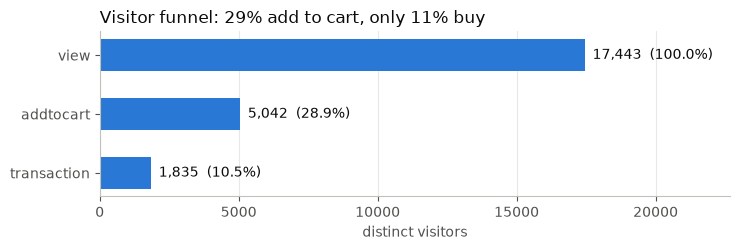

In [4]:
# Event funnel of the history part
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

funnel = (history.groupBy("event").agg(F.countDistinct("visitorid").alias("visitors"))
          .toPandas().set_index("event").loc[["view", "addtocart", "transaction"]])
fig, ax = plt.subplots(figsize=(7.5, 2.6))
bars = ax.barh(funnel.index[::-1], funnel["visitors"][::-1], color="#2a78d6", height=0.55)
for b, val in zip(bars, funnel["visitors"][::-1]):
    pct = val / funnel["visitors"].iloc[0] * 100
    ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f"  {val:,}  ({pct:.1f}%)",
            va="center", color="#0b0b0b", fontsize=10)
ax.set_xlabel("distinct visitors")
cart_pct = funnel["visitors"]["addtocart"] / funnel["visitors"]["view"] * 100
txn_pct = funnel["visitors"]["transaction"] / funnel["visitors"]["view"] * 100
ax.set_title(f"Visitor funnel: {cart_pct:.0f}% add to cart, only {txn_pct:.0f}% buy", loc="left", color="#0b0b0b", fontsize=12)
ax.grid(axis="x", color="#e9e8e4", linewidth=0.8); ax.set_axisbelow(True)
ax.set_xlim(0, funnel["visitors"].max() * 1.3)
plt.tight_layout(); plt.show()

### 5.3 Offline model: item-to-item collaborative filtering (batch)

For every visitor we take their strongest interaction with each item, $r_{v,i}=\max w(e)$. Two items co-occur when the same visitor touched both. The similarity is a cosine-style normalisation of co-occurrence by popularity, which stops best-sellers from being "similar" to everything:

$$
\text{co}(i,j) = \sum_{v} \min(r_{v,i}, r_{v,j}),
\qquad
\text{sim}(i,j) = \frac{\text{co}(i,j)}{\sqrt{\text{pop}(i)\,\text{pop}(j)}},
\qquad \text{pop}(i)=\sum_v r_{v,i}
$$

We keep the top-20 neighbours per item. This table is **small, static between retrains, and broadcast-joined** to the stream.

In [5]:
weight_col = (F.when(F.col("event") == "view", WEIGHTS["view"])
               .when(F.col("event") == "addtocart", WEIGHTS["addtocart"])
               .when(F.col("event") == "transaction", WEIGHTS["transaction"])
               .otherwise(0))

vi = history.withColumn("w", weight_col).groupBy("visitorid", "itemid").agg(F.max("w").alias("w"))
# ignore single-item visitors (no co-occurrence) and bots with huge baskets
active = vi.groupBy("visitorid").count().filter("count BETWEEN 2 AND 100").select("visitorid")
vi = vi.join(active, "visitorid")

a, b = vi.alias("a"), vi.alias("b")
pairs = (a.join(b, "visitorid")
          .filter(F.col("a.itemid") != F.col("b.itemid"))
          .groupBy(F.col("a.itemid").alias("item_a"), F.col("b.itemid").alias("item_b"))
          .agg(F.sum(F.least("a.w", "b.w")).alias("co"), F.count("*").alias("co_visitors")))

pop = history.withColumn("w", weight_col).groupBy("itemid", "visitorid").agg(F.max("w").alias("w")) \
             .groupBy("itemid").agg(F.sum("w").alias("pop"))
rank_w = Window.partitionBy("item_a").orderBy(F.desc("similarity"), F.desc("co_visitors"))
item_sim = (pairs
            .join(pop.select(F.col("itemid").alias("item_a"), F.col("pop").alias("pop_a")), "item_a")
            .join(pop.select(F.col("itemid").alias("item_b"), F.col("pop").alias("pop_b")), "item_b")
            .withColumn("similarity", F.col("co") / F.sqrt(F.col("pop_a") * F.col("pop_b")))
            .withColumn("rank", F.row_number().over(rank_w))
            .filter(F.col("rank") <= NEIGHBOURS)
            .select("item_a", "item_b", F.round("similarity", 4).alias("similarity"), "co_visitors")
            .cache())

popular = (pop.orderBy(F.desc("pop")).limit(50)
              .select(F.col("itemid").alias("rec_item"), F.col("pop").alias("pop_score")).cache())

print(f"item_sim rows: {item_sim.count():,}  |  items with neighbours: {item_sim.select('item_a').distinct().count():,}")
example_item = item_sim.groupBy("item_a").count().orderBy(F.desc("count"), "item_a").first()["item_a"]
print("Neighbours of item", example_item)
item_sim.filter(F.col("item_a") == example_item).orderBy(F.desc("similarity")).show(5)

item_sim rows: 29,995  |  items with neighbours: 1,500


Neighbours of item 1050


+------+------+----------+-----------+
|item_a|item_b|similarity|co_visitors|
+------+------+----------+-----------+
|  1050| 52760|    0.1233|         10|
|  1050| 82398|     0.115|         10|
|  1050|204576|    0.1109|         20|
|  1050|231779|    0.0982|          1|
|  1050| 42681|    0.0916|         10|
+------+------+----------+-----------+
only showing top 5 rows


### 5.4 Sliding windows on a real visitor (static preview)

The same `window()` function works on a static DataFrame, which is an easy way to see what the stream will do. With a 10-minute window sliding every 5 minutes, **every event lands in two overlapping windows**, so the rolling intent is re-evaluated every 5 minutes over the last 10.

visitor 585150


+--------+---------+------+------+---------+-------+
|time    |event    |itemid|weight|win_start|win_end|
+--------+---------+------+------+---------+-------+
|21:57:06|view     |345525|1     |21:50    |22:00  |
|21:57:06|view     |345525|1     |21:55    |22:05  |
|21:57:32|view     |100086|1     |21:50    |22:00  |
|21:57:32|view     |100086|1     |21:55    |22:05  |
|21:59:17|view     |345525|1     |21:50    |22:00  |
|21:59:17|view     |345525|1     |21:55    |22:05  |
|21:59:51|view     |193513|1     |21:50    |22:00  |
|21:59:51|view     |193513|1     |21:55    |22:05  |
|22:00:10|view     |264107|1     |21:55    |22:05  |
|22:00:10|view     |264107|1     |22:00    |22:10  |
|22:01:18|addtocart|264107|5     |21:55    |22:05  |
|22:01:18|addtocart|264107|5     |22:00    |22:10  |
|22:01:43|view     |345525|1     |21:55    |22:05  |
|22:01:43|view     |345525|1     |22:00    |22:10  |
|22:01:57|view     |345525|1     |21:55    |22:05  |
|22:01:57|view     |345525|1     |22:00    |22

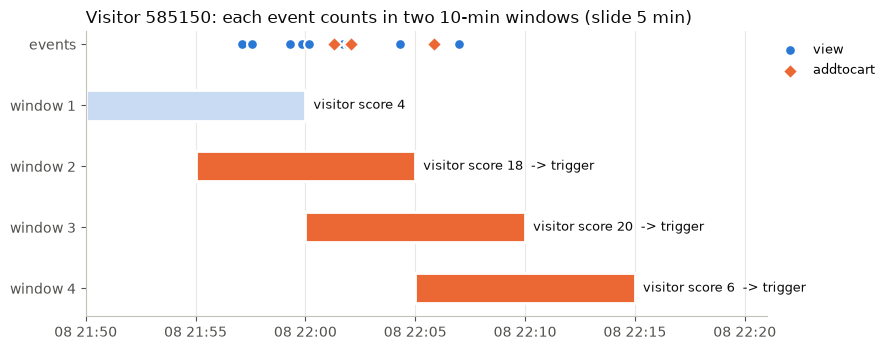

In [6]:
# pick a live visitor who added to cart, and show their events with the windows they fall into
demo_visitor = (live.filter("event = 'addtocart'").groupBy("visitorid").count()
                    .orderBy(F.desc("count"), "visitorid").first()["visitorid"])
demo = (live.filter(F.col("visitorid") == demo_visitor)
            .withColumn("event_time", F.timestamp_millis("timestamp"))
            .withColumn("weight", weight_col)
            .withColumn("win", F.window("event_time", WINDOW, SLIDE))
            .orderBy("event_time", "win"))
print("visitor", demo_visitor)
demo.select(F.date_format("event_time", "HH:mm:ss").alias("time"), "event", "itemid", "weight",
            F.date_format("win.start", "HH:mm").alias("win_start"),
            F.date_format("win.end", "HH:mm").alias("win_end")).show(30, truncate=False)

# visitor-level score per window, and whether any single item meets the trigger rule (score >= 5, no transaction)
item_win = demo.groupBy("win", "itemid").agg(F.sum("weight").alias("s"), F.sum((F.col("event") == "transaction").cast("int")).alias("t"))
per_win = (item_win.groupBy("win")
           .agg(F.sum("s").alias("intent"),
                F.max(((F.col("s") >= INTENT_THRESHOLD) & (F.col("t") == 0)).cast("int")).alias("trigger"))
           .orderBy("win").toPandas())
pts = demo.select("event_time", "event").distinct().toPandas()
fig, ax = plt.subplots(figsize=(9, 0.55 * len(per_win) + 1.4))
for k, r in per_win.iterrows():
    hit = bool(r["trigger"])
    ax.barh(k, (r["win"]["end"] - r["win"]["start"]), left=r["win"]["start"], height=0.5,
            color="#eb6834" if hit else "#c9daf3", edgecolor="white", linewidth=2)
    ax.text(r["win"]["end"], k, f"  visitor score {int(r['intent'])}" + ("  -> trigger" if hit else ""),
            va="center", fontsize=9, color="#0b0b0b")
ymark = {"view": -1.0, "addtocart": -1.0, "transaction": -1.0}
for ev, mk, col in [("view", "o", "#2a78d6"), ("addtocart", "D", "#eb6834"), ("transaction", "s", "#008300")]:
    s = pts[pts["event"] == ev]
    if len(s):
        ax.scatter(s["event_time"], [-1] * len(s), marker=mk, s=60, color=col, label=ev,
                   edgecolor="white", linewidth=1.5, zorder=3)
ax.set_yticks([-1] + list(range(len(per_win))), ["events"] + [f"window {k+1}" for k in range(len(per_win))])
ax.invert_yaxis(); ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=9)
ax.set_xlim(per_win["win"].map(lambda w: w["start"]).min(), per_win["win"].map(lambda w: w["end"]).max() + pd.Timedelta(minutes=6))
ax.set_title(f"Visitor {demo_visitor}: each event counts in two 10-min windows (slide 5 min)",
             loc="left", fontsize=12, color="#0b0b0b")
ax.grid(axis="x", color="#e9e8e4"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

### 5.5 The streaming pipeline

**Extract** (Kafka or replay files) → **Transform** (`from_json`, epoch-ms → `TimestampType`, weights, watermark, sliding-window aggregation) → **Recommend & Load** (`foreachBatch`).

First we prepare the replay: the live slice is cut into 15-minute files. Each line is exactly what `producer.py` sends to Kafka.

In [7]:
live_pdf = live.orderBy("timestamp").toPandas()
n_slices = int(STREAM_HOURS * 60 // SLICE_MINUTES)
live_pdf["slice"] = ((live_pdf["timestamp"] - split_ts) // (SLICE_MINUTES * 60_000)).clip(upper=n_slices - 1)

def to_payload(r):
    return json.dumps({"timestamp": int(r.timestamp), "visitorid": int(r.visitorid), "event": r.event,
                       "itemid": int(r.itemid),
                       "transactionid": None if pd.isna(r.transactionid) else int(r.transactionid)})

slices = [(s, g) for s, g in live_pdf.groupby("slice")]
print(f"{len(slices)} replay slices; first payloads:")
for line in slices[0][1].head(3).itertuples():
    print("  ", to_payload(line))

12 replay slices; first payloads:
   {"timestamp": 1433797642426, "visitorid": 1248403, "event": "view", "itemid": 208432, "transactionid": null}
   {"timestamp": 1433797646400, "visitorid": 1170580, "event": "view", "itemid": 354916, "transactionid": null}
   {"timestamp": 1433797647254, "visitorid": 877695, "event": "view", "itemid": 392237, "transactionid": null}


**Kafka version of the source** (used in the full project; everything after `raw` is identical):

```python
raw = (spark.readStream.format("kafka")
       .option("kafka.bootstrap.servers", "localhost:9092")
       .option("subscribe", "retail-rocket-events")      # topic with 2 partitions
       .option("startingOffsets", "latest")
       .option("maxOffsetsPerTrigger", 5000)              # back-pressure per micro-batch
       .load()
       .selectExpr("CAST(value AS STRING) AS value", "partition", "offset"))
```

In [8]:
# ---- EXTRACT ----------------------------------------------------------------
if SOURCE == "kafka":
    raw = (spark.readStream.format("kafka")
           .option("kafka.bootstrap.servers", KAFKA_BOOTSTRAP)
           .option("subscribe", KAFKA_TOPIC)
           .option("startingOffsets", "latest")
           .option("maxOffsetsPerTrigger", 5000)
           .load()
           .selectExpr("CAST(value AS STRING) AS value"))
else:
    raw = (spark.readStream.format("text")
           .option("maxFilesPerTrigger", 1)        # 1 replay file = 1 micro-batch
           .load(str(STREAM_DIR)))                  # column: value (string)

# ---- TRANSFORM: parse + typed event time + weights ---------------------------
parsed = (raw
          .select(F.from_json("value", EVENT_SCHEMA).alias("e"))
          .select("e.*")
          .filter(F.col("visitorid").isNotNull() & F.col("event").isin(*WEIGHTS))   # drop malformed
          .withColumn("event_time", F.timestamp_millis("timestamp"))                  # ms -> TimestampType
          .withColumn("weight", weight_col)
          .withColumn("is_view", (F.col("event") == "view").cast("int"))
          .withColumn("is_cart", (F.col("event") == "addtocart").cast("int"))
          .withColumn("is_txn",  (F.col("event") == "transaction").cast("int")))

# ---- TRANSFORM: watermark + sliding-window intent per visitor x item ---------
intent = (parsed
          .withWatermark("event_time", WATERMARK)
          .groupBy(F.window("event_time", WINDOW, SLIDE).alias("window"), "visitorid", "itemid")
          .agg(F.sum("weight").alias("intent_score"),
               F.sum("is_view").alias("views"),
               F.sum("is_cart").alias("carts"),
               F.sum("is_txn").alias("txns"),
               F.max("event_time").alias("last_event_time")))

print("isStreaming:", intent.isStreaming)
intent.printSchema()

isStreaming: True
root
 |-- window: struct (nullable = true)
 |    |-- start: timestamp (nullable = true)
 |    |-- end: timestamp (nullable = true)
 |-- visitorid: integer (nullable = true)
 |-- itemid: integer (nullable = true)
 |-- intent_score: long (nullable = true)
 |-- views: long (nullable = true)
 |-- carts: long (nullable = true)
 |-- txns: long (nullable = true)
 |-- last_event_time: timestamp (nullable = true)



#### Recommendation logic inside `foreachBatch`

For each micro-batch Spark hands us a **static** DataFrame with the windows whose score changed. Inside it we can use any batch operation:

1. **Filter high intent**: `intent_score ≥ 5 AND txns = 0`; keep the latest window per `(visitor, item)` (sliding windows duplicate rows).
2. **Candidate generation**: broadcast-join the seed items with `item_sim`.
3. **Exclude** items the visitor already touched in this batch.
4. **Score & rank**: $\text{rec}(v,j)=\sum_{i\in\text{seeds}(v)} \text{sim}(i,j)\cdot\text{Intent}(v,i)$, top-$K$ per visitor with `row_number()`.
5. **Fallback**: visitors whose seed items have no neighbours (new items, cold start) get popular items.
6. **Load**: write to Parquet partitioned by `event_date` / `batch_id` (dynamic overwrite → idempotent replays), and **log batch metadata**.

In [9]:
# ---- structured logger: console + file ---------------------------------------
logger = logging.getLogger("rec_engine")
logger.handlers.clear(); logger.setLevel(logging.INFO); logger.propagate = False
fh = logging.FileHandler(LOG_DIR / "recommendation_batches.log")
fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
logger.addHandler(fh)

batch_results = {}      # batch_id -> pandas DataFrame of recommendations (for display in the notebook)
batch_meta = []

def recommend_batch(batch_df, batch_id):
    t0 = time.perf_counter()
    batch_df = batch_df.persist()
    changed_rows = batch_df.count()

    # 1. high-intent seeds (latest window per visitor x item)
    latest = Window.partitionBy("visitorid", "itemid").orderBy(F.col("window.end").desc())
    seeds = (batch_df
             .filter((F.col("intent_score") >= INTENT_THRESHOLD) & (F.col("txns") == 0))
             .withColumn("rn", F.row_number().over(latest)).filter("rn = 1")
             .select("visitorid", F.col("itemid").alias("seed_item"), "intent_score", "views", "carts",
                     F.col("window.start").alias("window_start"), F.col("window.end").alias("window_end")))

    # 2-3. candidates from item_sim, excluding items already seen in this batch
    seen = batch_df.select("visitorid", F.col("itemid").alias("rec_item")).distinct()
    cand = (seeds.join(F.broadcast(item_sim), seeds.seed_item == item_sim.item_a)
                 .select("visitorid", F.col("item_b").alias("rec_item"), "seed_item",
                         (F.col("similarity") * F.col("intent_score")).alias("s"))
                 .join(seen, ["visitorid", "rec_item"], "left_anti"))

    # 4. score + top-K per visitor
    by_visitor = Window.partitionBy("visitorid").orderBy(F.desc("rec_score"), "rec_item")
    cf_recs = (cand.groupBy("visitorid", "rec_item")
                   .agg(F.round(F.sum("s"), 4).alias("rec_score"))
                   .withColumn("rank", F.row_number().over(by_visitor))
                   .filter(F.col("rank") <= TOP_K)
                   .withColumn("source", F.lit("item_cf")))

    # 5. popularity fallback for visitors with no CF candidates
    missing = seeds.select("visitorid").distinct().join(cf_recs.select("visitorid").distinct(), "visitorid", "left_anti")
    fb_rank = Window.partitionBy("visitorid").orderBy(F.desc("pop_score"), "rec_item")
    fb_recs = (missing.crossJoin(F.broadcast(popular))
                      .join(seen, ["visitorid", "rec_item"], "left_anti")
                      .withColumn("rank", F.row_number().over(fb_rank)).filter(F.col("rank") <= TOP_K)
                      .select("visitorid", "rec_item", F.lit(0.0).alias("rec_score"), "rank",
                              F.lit("popular").alias("source")))

    ctx = (seeds.groupBy("visitorid")
                .agg(F.collect_set("seed_item").alias("seed_items"),
                     F.max("intent_score").alias("max_intent"),
                     F.max("carts").alias("carts"),
                     F.max("window_end").alias("window_end")))
    recs = (cf_recs.unionByName(fb_recs).join(ctx, "visitorid")
            .withColumn("trigger_reason", F.when(F.col("carts") > 0, "cart_no_purchase").otherwise("heavy_browsing"))
            .withColumn("batch_id", F.lit(batch_id))
            .withColumn("generated_at", F.current_timestamp())
            .withColumn("event_date", F.to_date("window_end"))
            .drop("carts"))

    # 6. load: idempotent, partitioned parquet (re-running the same batch_id overwrites, never duplicates)
    recs = recs.persist()
    n_recs = recs.count()
    if n_recs:
        recs.write.mode("overwrite").partitionBy("event_date", "batch_id").parquet(str(OUT_DIR))
    pdf = recs.orderBy("visitorid", "rank").toPandas()
    batch_results[batch_id] = pdf

    meta = {"batch_id": batch_id, "changed_window_rows": changed_rows,
            "triggered_visitors": int(pdf["visitorid"].nunique()) if n_recs else 0,
            "recommendations": n_recs, "fallback_visitors": int(pdf.loc[pdf.source == "popular", "visitorid"].nunique()) if n_recs else 0,
            "foreachBatch_ms": round((time.perf_counter() - t0) * 1000)}
    batch_meta.append(meta)
    logger.info(json.dumps(meta))
    recs.unpersist(); batch_df.unpersist()

In [10]:
query = (intent.writeStream
         .queryName("intent_recommender")
         .outputMode("update")                                   # emit windows as soon as they change
         .foreachBatch(recommend_batch)
         .option("checkpointLocation", str(CKPT_DIR / "intent_recommender"))
         .trigger(processingTime="1 second")
         .start())
print("query started:", query.name, "| id:", query.id)

query started: intent_recommender | id: 9314da21-eee9-46ce-8bfd-cb9c76ea56b8


#### Live replay

Each step drops one 15-minute slice of events into the source (in the full project: `producer.py` publishing to Kafka) and waits for Spark to process it. Watch the watermark advance and recommendations appear **in the same micro-batch** in which a visitor crosses the threshold.

> Between data batches Spark also runs **no-data batches** (`input_rows = 0`): after the watermark moves, it runs one extra batch to finalise windows and evict their state. They show up in the progress table below.

In [11]:
def publish_slice(idx, g):
    path = STREAM_DIR / f"slice_{idx:03d}.json"
    tmp = STREAM_DIR / f".slice_{idx:03d}.tmp"
    tmp.write_text("\n".join(to_payload(r) for r in g.itertuples()) + "\n")
    tmp.rename(path)                     # atomic move: Spark never sees half-written files
    return path

def show_new_batches(seen_ids, max_visitors=2):
    for bid in sorted(set(batch_results) - seen_ids):
        pdf = batch_results[bid]
        seen_ids.add(bid)
        if pdf.empty:
            continue
        for v, g in list(pdf.groupby("visitorid"))[:max_visitors]:
            r = g.iloc[0]
            items = ", ".join(f"{int(i)}" for i in g["rec_item"])
            print(f"      visitor {v:<8} reason={r.trigger_reason:<16} intent={int(r.max_intent):<3} "
                  f"seeds={list(map(int, r.seed_items))}  ->  [{items}]  ({r.source})")
        more = pdf["visitorid"].nunique() - max_visitors
        if more > 0:
            print(f"      ... and {more} more visitor(s)")

shown = set()
for idx, g in slices:
    publish_slice(idx, g)
    query.processAllAvailable()
    p = query.lastProgress or {}
    wm = (p.get("eventTime") or {}).get("watermark", "-")
    t_from = pd.to_datetime(g.timestamp.min(), unit="ms").strftime("%H:%M")
    t_to = pd.to_datetime(g.timestamp.max(), unit="ms").strftime("%H:%M")
    print(f"slice {idx:02d} | events {t_from}-{t_to} | {len(g):>4} events | watermark {wm[11:19] if wm != '-' else wm}")
    show_new_batches(shown)

slice 00 | events 21:07-21:22 |  175 events | watermark 21:17:12
      visitor 46131    reason=cart_no_purchase intent=6   seeds=[219193]  ->  [437622, 49974, 341787, 396404, 41004]  (item_cf)
      visitor 79615    reason=cart_no_purchase intent=6   seeds=[349901]  ->  [49974, 437622, 297383, 460269, 341787]  (item_cf)
      ... and 6 more visitor(s)


slice 01 | events 21:22-21:37 |  148 events | watermark 21:32:17
      visitor 59623    reason=cart_no_purchase intent=8   seeds=[345525]  ->  [246420, 193513, 299777, 221279, 264107]  (item_cf)
      visitor 105128   reason=cart_no_purchase intent=6   seeds=[92351]  ->  [276268, 45105, 447161, 74565, 309981]  (item_cf)
      ... and 3 more visitor(s)


slice 02 | events 21:37-21:51 |   99 events | watermark 21:46:56
      visitor 383311   reason=cart_no_purchase intent=6   seeds=[228099]  ->  [423213, 58281, 32774, 207978, 205439]  (item_cf)
      visitor 635233   reason=cart_no_purchase intent=7   seeds=[92351, 251869]  ->  [276268, 74565, 309981, 447161, 360057]  (item_cf)
      ... and 1 more visitor(s)


slice 03 | events 21:52-22:07 |  180 events | watermark 22:02:01
      visitor 412914   reason=cart_no_purchase intent=7   seeds=[228099, 200234]  ->  [423213, 235201, 58281, 32774, 207978]  (item_cf)
      visitor 490524   reason=cart_no_purchase intent=7   seeds=[228099, 434736]  ->  [66109, 414209, 423213, 235201, 411133]  (item_cf)
      ... and 6 more visitor(s)


slice 04 | events 22:07-22:22 |  102 events | watermark 22:17:12
      visitor 299907   reason=cart_no_purchase intent=7   seeds=[66942]  ->  [79960, 353065, 332117, 285491, 113799]  (item_cf)
      visitor 1086802  reason=cart_no_purchase intent=6   seeds=[255378]  ->  [85868, 60938, 312216, 243722, 330969]  (item_cf)
      ... and 1 more visitor(s)


...

slice 07 | events 22:52-23:07 |  158 events | watermark 23:02:18
      visitor 123536   reason=cart_no_purchase intent=6   seeds=[431270, 62777]  ->  [39517, 47935, 52347, 157745, 36792]  (item_cf)
      visitor 174792   reason=cart_no_purchase intent=6   seeds=[385961]  ->  [409695, 202092, 153671, 149309, 427748]  (item_cf)
      ... and 10 more visitor(s)


slice 08 | events 23:07-23:22 |  248 events | watermark 23:17:17
      visitor 174792   reason=cart_no_purchase intent=6   seeds=[330969]  ->  [312216, 243722, 394311, 44834, 127404]  (item_cf)
      visitor 395865   reason=cart_no_purchase intent=9   seeds=[354916]  ->  [69915, 413439, 329152, 356639, 353904]  (item_cf)
      ... and 7 more visitor(s)


slice 09 | events 23:22-23:37 |  133 events | watermark 23:32:14
      visitor 72421    reason=cart_no_purchase intent=6   seeds=[171546]  ->  [371305, 216988, 426871, 460371, 315574]  (item_cf)
      visitor 844222   reason=cart_no_purchase intent=9   seeds=[182584]  ->  [341048, 76687, 208432, 114921, 142065]  (item_cf)
      ... and 1 more visitor(s)


slice 10 | events 23:37-23:52 |   80 events | watermark 23:47:06
      visitor 44030    reason=cart_no_purchase intent=6   seeds=[150255]  ->  [225419, 410444, 251869, 74565, 126523]  (item_cf)
      visitor 196139   reason=cart_no_purchase intent=6   seeds=[244641]  ->  [146995, 31507, 11245, 353596, 329518]  (item_cf)
      ... and 2 more visitor(s)


slice 11 | events 23:52-00:07 |  103 events | watermark 00:02:19
      visitor 426999   reason=cart_no_purchase intent=6   seeds=[356835]  ->  [379294, 339975, 130175, 207137, 228256]  (item_cf)
      visitor 684036   reason=cart_no_purchase intent=6   seeds=[284445]  ->  [123227, 52760, 180545, 6473, 78148]  (item_cf)


In [12]:
# Micro-batch metadata: Spark's own progress reports + our foreachBatch log
prog = pd.DataFrame([{
    "batch_id": p["batchId"],
    "input_rows": p["numInputRows"],
    "trigger_ms": p["durationMs"].get("triggerExecution"),
    "watermark": (p.get("eventTime") or {}).get("watermark", "")[11:19],
    "state_rows": sum(s.get("numRowsTotal", 0) for s in p.get("stateOperators", [])),
    "late_dropped": sum(s.get("numRowsDroppedByWatermark", 0) for s in p.get("stateOperators", [])),
} for p in query.recentProgress])
meta = pd.DataFrame(batch_meta)
batch_report = prog.merge(meta, on="batch_id", how="left")
batch_report.tail(15)

,batch_id,input_rows,trigger_ms,watermark,state_rows,late_dropped,changed_window_rows,triggered_visitors,recommendations,fallback_visitors,foreachBatch_ms
9,9,0,4738,22:17:12,721,0,0,0,0,0,4368
10,10,125,5662,22:17:12,2072,0,199,6,30,0,5211
11,11,0,5039,22:32:16,889,0,0,0,0,0,4728
12,12,177,5434,22:32:16,2849,0,283,11,55,0,5081
13,13,0,4562,22:47:18,1386,0,0,0,0,0,4315
14,14,158,5879,22:47:18,3094,0,250,12,60,0,5306
15,15,0,4551,23:02:18,1155,0,0,0,0,0,4303
16,16,248,5913,23:02:18,4046,0,418,9,45,0,5509
17,17,0,4844,23:17:17,1995,0,0,0,0,0,4404
18,18,133,6085,23:17:17,3591,0,233,3,15,0,5576


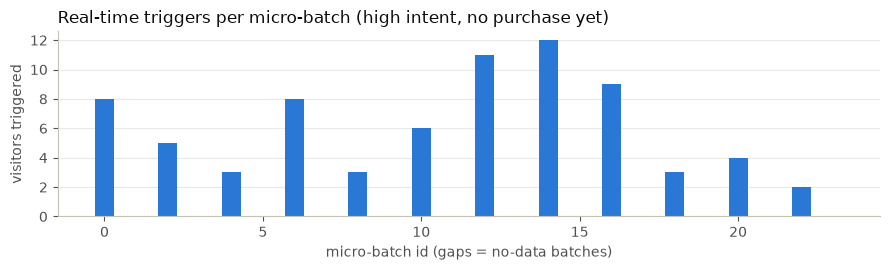

['2026-10-22 09:36:34,958 INFO {"batch_id": 21, "changed_window_rows": 0, "triggered_visitors": 0, "recommendations": 0, "fallback_visitors": 0, "foreachBatch_ms": 4476}', '2026-10-22 09:36:41,168 INFO {"batch_id": 22, "changed_window_rows": 165, "triggered_visitors": 2, "recommendations": 10, "fallback_visitors": 0, "foreachBatch_ms": 4896}', '2026-10-22 09:36:46,416 INFO {"batch_id": 23, "changed_window_rows": 0, "triggered_visitors": 0, "recommendations": 0, "fallback_visitors": 0, "foreachBatch_ms": 5014}']


In [13]:
fig, ax = plt.subplots(figsize=(9, 2.8))
br = batch_report.dropna(subset=["recommendations"])
ax.bar(br["batch_id"], br["triggered_visitors"], color="#2a78d6", width=0.6)
ax.set_xlabel("micro-batch id (gaps = no-data batches)"); ax.set_ylabel("visitors triggered")
from matplotlib.ticker import MaxNLocator
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Real-time triggers per micro-batch (high intent, no purchase yet)", loc="left", fontsize=12, color="#0b0b0b")
ax.grid(axis="y", color="#e9e8e4"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
print(open(LOG_DIR / "recommendation_batches.log").read().splitlines()[-3:])

#### Late-arriving data and the watermark

We now inject two **out-of-order** add-to-cart events for two new visitors:

- **A**: 2 minutes behind the latest event time → still inside the 5-minute watermark → **accepted**, can trigger a recommendation.
- **B**: 20 minutes behind → its windows are already finalised → **dropped** (counted in `numRowsDroppedByWatermark`).

In [14]:
max_seen = int(live_pdf["timestamp"].max())
seed_item = int(example_item)
late = pd.DataFrame([
    {"timestamp": max_seen - 2 * 60_000,  "visitorid": 900000001, "event": "addtocart", "itemid": seed_item, "transactionid": None},
    {"timestamp": max_seen - 20 * 60_000, "visitorid": 900000002, "event": "addtocart", "itemid": seed_item, "transactionid": None},
])
before_id = query.lastProgress["batchId"]
publish_slice(998, late)
query.processAllAvailable()

new_prog = [p for p in query.recentProgress if p["batchId"] > before_id]
dropped = sum(s.get("numRowsDroppedByWatermark", 0) for p in new_prog for s in p["stateOperators"])
print("watermark                :", query.lastProgress["eventTime"].get("watermark"))
print("input rows               :", sum(p["numInputRows"] for p in new_prog))
print("numRowsDroppedByWatermark:", dropped)
all_recs = pd.concat(batch_results.values(), ignore_index=True)
for v in (900000001, 900000002):
    got = all_recs[all_recs.visitorid == v]
    print(f"visitor {v}: " + (f"recommended {got.rec_item.astype(int).tolist()}" if len(got) else "no recommendation (event too late)"))

watermark                : 2015-06-09T00:02:19.353Z
input rows               : 2
numRowsDroppedByWatermark: 14
visitor 900000001: recommended [52760, 82398, 204576, 231779, 42681]
visitor 900000002: no recommendation (event too late)


---
## 6. Fault tolerance & exactly-once for recommendations

| Mechanism | What it guarantees here |
|---|---|
| **Replayable source** (Kafka offsets / file list) | Data for an unfinished batch can be re-read |
| **Checkpoint** (`offsets/`, `commits/`, `state/`) | Which offsets each batch covered, and the window state (RocksDB) |
| **Deterministic batch** | Re-running batch *n* reads the same offsets and state, so it yields the same output |
| **Idempotent sink** (overwrite partition `batch_id=n`) | A replayed batch replaces its own output instead of duplicating it → **end-to-end exactly-once** output |

`foreachBatch` on its own is **at-least-once**: if the driver crashes after writing but before committing, batch *n* runs again. Keying the write by `batch_id` (or using Delta Lake's `txnAppId`/`txnVersion`) turns that into exactly-once. Pushing to an external system (e-mail, push) should carry a dedup key `(visitorid, window_end)` for the same reason.

**Demo:** stop the query, restart it with the **same checkpoint**, then publish one more slice. The batch id continues and old files are **not** reprocessed.

In [15]:
last_batch = query.lastProgress["batchId"]
query.stop()
print("stopped after batch", last_batch, "| checkpoint contents:",
      sorted(os.listdir(CKPT_DIR / "intent_recommender")))

query = (intent.writeStream.queryName("intent_recommender_restarted").outputMode("update")
         .foreachBatch(recommend_batch)
         .option("checkpointLocation", str(CKPT_DIR / "intent_recommender"))   # same checkpoint
         .trigger(processingTime="1 second").start())
query.processAllAvailable()
print("after restart, rows re-read from old files:", sum(p["numInputRows"] for p in query.recentProgress))

extra = live_pdf.tail(40).copy()
extra["timestamp"] = extra["timestamp"] + 60_000          # one more minute of traffic
publish_slice(999, extra)
query.processAllAvailable()
data_batches = [(p["batchId"], p["numInputRows"]) for p in query.recentProgress if p["numInputRows"] > 0]
print("batches that read data after restart (batch_id, rows):", data_batches, "-> only the new file, ids continue")
query.stop()

stopped after batch 24 | checkpoint contents: ['.metadata.crc', 'commits', 'metadata', 'offsets', 'sources', 'state']
after restart, rows re-read from old files: 0


batches that read data after restart (batch_id, rows): [(25, 40)] -> only the new file, ids continue


In [16]:
# The curated sink: partitioned parquet, read back as an ordinary batch table
out = spark.read.parquet(str(OUT_DIR))
print("partitions:", sorted({p.split("/")[0] for p in os.listdir(OUT_DIR) if "=" in p}))
print("rows:", out.count(), "| visitors:", out.select("visitorid").distinct().count())
out.groupBy("trigger_reason", "source").agg(F.countDistinct("visitorid").alias("visitors")).orderBy("trigger_reason", "source").show()

# How many triggered visitors were unknown to the batch history? (a nightly user-based model could not serve them)
hist_visitors = history.select("visitorid").distinct()
trig = out.select("visitorid").distinct()
new_share = trig.join(hist_visitors, "visitorid", "left_anti").count() / max(trig.count(), 1)
print(f"triggered visitors with NO prior history: {new_share:.0%}")

out.select("visitorid", "seed_items", "max_intent", "trigger_reason", "rank", "rec_item", "rec_score", "source", "batch_id") \
   .orderBy("batch_id", "visitorid", "rank").show(10, truncate=False)

partitions: ['event_date=2015-06-08', 'event_date=2015-06-09']


rows: 385 | visitors: 72


+----------------+-------+--------+
|  trigger_reason| source|visitors|
+----------------+-------+--------+
|cart_no_purchase|item_cf|      68|
|  heavy_browsing|item_cf|       4|
+----------------+-------+--------+



triggered visitors with NO prior history: 86%


+---------+----------+----------+----------------+----+--------+---------+-------+--------+
|visitorid|seed_items|max_intent|trigger_reason  |rank|rec_item|rec_score|source |batch_id|
+---------+----------+----------+----------------+----+--------+---------+-------+--------+
|46131    |[219193]  |6         |cart_no_purchase|1   |437622  |1.4106   |item_cf|0       |
|46131    |[219193]  |6         |cart_no_purchase|2   |49974   |1.3014   |item_cf|0       |
|46131    |[219193]  |6         |cart_no_purchase|3   |341787  |1.26     |item_cf|0       |
|46131    |[219193]  |6         |cart_no_purchase|4   |396404  |1.2282   |item_cf|0       |
|46131    |[219193]  |6         |cart_no_purchase|5   |41004   |1.095    |item_cf|0       |
|79615    |[349901]  |6         |cart_no_purchase|1   |49974   |0.672    |item_cf|0       |
|79615    |[349901]  |6         |cart_no_purchase|2   |437622  |0.6714   |item_cf|0       |
|79615    |[349901]  |6         |cart_no_purchase|3   |297383  |0.6156   |item_c

---
## 7. Serving, evaluation & challenges

### 7.1 Where the recommendation goes

| Target | Latency | Notes |
|---|---|---|
| Kafka topic `recommendations` | ~ms | Website / push service consumes it; best decoupling |
| Key-value store (Redis, Cassandra) keyed by `visitorid` | ~ms read | Website reads on next page view |
| Parquet / Delta (this notebook) | minutes | Analytics, A/B evaluation, retraining input |
| Console sink | — | Classroom debugging only (prints in the driver log) |

### 7.2 How to evaluate

| Metric | Offline (replay history) | Online (A/B test) |
|---|---|---|
| Relevance | Precision@K, Recall@K, HitRate@K, NDCG on the next item the visitor touched | CTR on the widget |
| Business | — | Add-to-cart rate, conversion rate, revenue per session |
| System | Batch duration, end-to-end latency (event time → `generated_at`), state size | p95 latency, consumer lag |

### 7.3 Challenges and how this design addresses them

| Challenge | Risk | Mitigation |
|---|---|---|
| Unbounded state | Memory grows per visitor x item x window | Watermark (5 min) + RocksDB state store |
| Late / out-of-order events | Wrong or missing scores | Event-time windows + watermark trade-off (5.5 demo) |
| Duplicate triggers | Sliding windows and update mode re-emit a visitor | Keep latest window per visitor-item; dedup key `(visitorid, window_end)` at serving |
| Cold-start items | No neighbours in `item_sim` | Popularity fallback; content-based similarity on item properties |
| Stale offline model | New products never recommended | Periodic retrain from the Parquet sink (Lambda-style batch layer) |
| Skewed keys / bots | Hot partitions, polluted similarity | Cap basket size (≤ 100 items), bot filtering upstream |
| Hard window edges | Score drops abruptly | Exponential decay with `transformWithStateInPandas` |
| Feedback loops / popularity bias | Same items recommended forever | Similarity normalised by popularity; exploration slots |

### 7.4 Possible extensions

- Session-based neural models (GRU4Rec, Hidasi et al., 2016) served via `mapInPandas` / `pandas_udf` inside `foreachBatch`.
- ALS on implicit feedback (`pyspark.ml.recommendation.ALS(implicitPrefs=True)`) retrained hourly; the stream folds in live intent.
- A second streaming query for **trending items** (windowed `count()` per item) to make the fallback live as well.

---
## 8. Summary

- Real-time recommendation is about **acting inside the session**. Batch models are accurate but late and blind to first-time visitors; streaming adds current context in seconds.
- Spark lets one team write the **offline model** (item-to-item CF) and the **online scoring** (windowed intent) with the **same DataFrame API**.
- Intent = weighted sum (view 1, add-to-cart 5, transaction 10) per visitor × item over a **10-minute window sliding every 5 minutes**, bounded by a **5-minute watermark**.
- `outputMode("update")` + `foreachBatch` triggers recommendations in the **same micro-batch** in which a visitor crosses the threshold, and makes ranking, fallback, logging and idempotent Parquet writes possible.
- Checkpointing + replayable source + `batch_id`-keyed writes give **exactly-once** recommendation output.

### References

1. Armbrust, M., Das, T., Torres, J., Yavuz, B., Zhu, S., Xin, R., Ghodsi, A., Stoica, I., & Zaharia, M. (2018). *Structured Streaming: A Declarative API for Real-Time Applications in Apache Spark.* Proceedings of ACM SIGMOD 2018, 601–613.
2. Zaharia, M., Das, T., Li, H., Hunter, T., Shenker, S., & Stoica, I. (2013). *Discretized Streams: Fault-Tolerant Streaming Computation at Scale.* Proceedings of SOSP 2013.
3. Linden, G., Smith, B., & York, J. (2003). *Amazon.com Recommendations: Item-to-Item Collaborative Filtering.* IEEE Internet Computing, 7(1), 76–80.
4. Hu, Y., Koren, Y., & Volinsky, C. (2008). *Collaborative Filtering for Implicit Feedback Datasets.* Proceedings of IEEE ICDM 2008, 263–272.
5. Koren, Y., Bell, R., & Volinsky, C. (2009). *Matrix Factorization Techniques for Recommender Systems.* Computer, 42(8), 30–37.
6. Hidasi, B., Karatzoglou, A., Baltrunas, L., & Tikk, D. (2016). *Session-based Recommendations with Recurrent Neural Networks.* ICLR 2016.
7. Ludewig, M., & Jannach, D. (2018). *Evaluation of Session-based Recommendation Algorithms.* User Modeling and User-Adapted Interaction, 28(4–5), 331–390.
8. Covington, P., Adams, J., & Sargin, E. (2016). *Deep Neural Networks for YouTube Recommendations.* Proceedings of ACM RecSys 2016.
9. Kreps, J. (2014). *Questioning the Lambda Architecture.* O'Reilly Radar.
10. Marz, N., & Warren, J. (2015). *Big Data: Principles and Best Practices of Scalable Realtime Data Systems.* Manning.
11. Apache Spark. *Structured Streaming Programming Guide* and *Structured Streaming + Kafka Integration Guide* (Spark 4.0 documentation).
12. Retail Rocket. *Retailrocket recommender system dataset.* Kaggle.

In [17]:
spark.stop()